# Passo 1 – Os dados e a separação do tempo

O trabalho tem **duas fases**:

| Fase | O que decide | Critério | Custo? |
|---|---|---|---|
| **A – RF ingênua** | candle, alvo, variáveis, janela, re-treino, hiperparâmetros | **R² fora da amostra** (quanto erra menos que prever zero) | ❌ nunca |
| **B – lucro** | só a regra de operação (quando entrar) | esperança por operação após o custo | ✅ 5 pts por operação |

No fim, só para **comparação**, medimos quanto cada candle lucraria.

Este passo apenas descreve os dados: **não toma nenhuma decisão**.

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import rf_zero as rz
win_1m = rz.carregar("../../dados/WINN_M1/WIN$N_M1.csv")
print(win_1m.index.min(), "→", win_1m.index.max(), "|", len(win_1m), "candles de 1 min no pregão regular")

2020-10-15 11:49:00 → 2026-09-25 17:59:00 | 733513 candles de 1 min no pregão regular


## 1.1 A separação do tempo (mantida do projeto)

Nunca embaralhamos: o modelo só aprende com o passado e é avaliado no futuro.

In [2]:
base = rz.adicionar_alvo(win_1m)
partes = {"treino (até 2023)": base[base.index < rz.VALIDACAO[0]],
          "validação (2024)": rz.periodo(base, rz.VALIDACAO),
          "teste (01/25–03/26)": rz.periodo(base, rz.TESTE),
          "extra (04/26–09/26)": rz.periodo(base, rz.EXTRA)}
pd.DataFrame({k: {"início": v.index.min().date(), "fim": v.index.max().date(),
                  "candles 1 min": len(v), "pregões": v.index.normalize().nunique()}
              for k, v in partes.items()}).T

,início,fim,candles 1 min,pregões
treino (até 2023),2020-10-15,2023-12-28,365104,683
validação (2024),2024-01-02,2024-12-30,135280,251
teste (01/25–03/26),2025-01-02,2026-03-31,167136,311
extra (04/26–09/26),2026-04-01,2026-09-25,65993,123


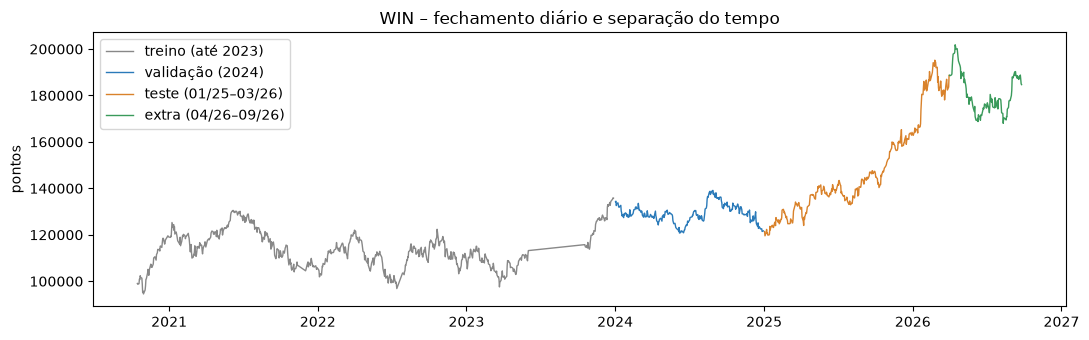

In [3]:
fig, ax = plt.subplots(figsize=(11, 3.5))
for (nome, p), c in zip(partes.items(), ["#888", "#2a7ab9", "#d9822b", "#3a9a5b"]):
    d = p["close"].resample("D").last().dropna()
    ax.plot(d.index, d.values, color=c, label=nome, lw=1)
ax.set_title("WIN – fechamento diário e separação do tempo"); ax.set_ylabel("pontos"); ax.legend(loc="upper left")
plt.tight_layout(); plt.savefig("passo01_separacao.png", dpi=120); plt.show()

## 1.2 Como são os candles de cada tamanho (período de treino)

Juntamos os candles de 1 min em 5, 15, 30 e 60 min e medimos, para cada candle *t*, o movimento até o fechamento seguinte: |close(t+1) − close(t)|.
É só uma descrição: **todos os candles seguem para os testes da Fase A**.

In [4]:
treino_1m = win_1m[win_1m.index < rz.VALIDACAO[0]]
linhas = {}
for m in [1, 5, 15, 30, 60]:
    b = rz.adicionar_alvo(rz.reamostrar(treino_1m, m)).dropna(subset=["mov_prox"])
    linhas[f"{m} min"] = {"candles no treino": len(b), "candles/dia": round(len(b) / b.index.normalize().nunique()),
                          "movimento médio (pts)": b["mov_prox"].abs().mean(),
                          "movimento médio (%)": b["ret_prox"].abs().mean()}
desc = pd.DataFrame(linhas).T
desc.round(3)

,candles no treino,candles/dia,movimento médio (pts),movimento médio (%)
1 min,364421.0,534.0,40.846,0.036
5 min,72372.0,106.0,92.024,0.082
15 min,23807.0,35.0,157.278,0.140
30 min,11563.0,17.0,224.152,0.199
60 min,5441.0,8.0,323.361,0.287


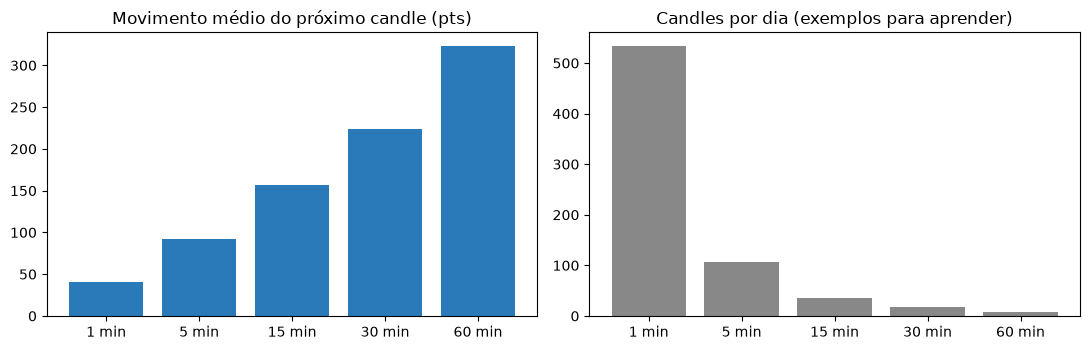

In [5]:
fig, axs = plt.subplots(1, 2, figsize=(11, 3.6))
axs[0].bar(desc.index, desc["movimento médio (pts)"], color="#2a7ab9"); axs[0].set_title("Movimento médio do próximo candle (pts)")
axs[1].bar(desc.index, desc["candles/dia"], color="#888"); axs[1].set_title("Candles por dia (exemplos para aprender)")
plt.tight_layout(); plt.savefig("passo01_candles.png", dpi=120); plt.show()

## Conclusões do Passo 1

1. **Separação do tempo:** treino até 2023 (683 pregões; a base tem buracos, o maior em jun–out/2023), validação 2024 (251), teste 01/2025–03/2026 (311) e um período extra 04–09/2026 (123).
2. **Candles maiores andam mais, mas há muito menos deles:** de 41 pts e 534 candles/dia (1 min) a 323 pts e 8 candles/dia (60 min). Mais exemplos ajudam a árvore a aprender; movimentos maiores podem carregar mais padrão – quem decide é o R² nos próximos testes.
3. **Nenhuma decisão aqui.** Os 5 tamanhos de candle seguem para a Fase A. O custo só aparece na Fase B.